<a href="https://colab.research.google.com/github/Annette-1/SIMULACION-II/blob/main/SIR_con_PyMC_optimizado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# <span style="color:brown;">**Modelo SIR: Ajuste de parámetros del modelo SIR**</span>
<span style="color:purple;"></span>

<span style="color:blue;">**Nombre: Jerónimo López Annette Michelle**</span>

<span style="color:blue;"> **Objetivo:** </span> *Estimar los parámetros $a$ (tasa de transmisión) y $b$ (tasa de recuperación) del modelo SIR que mejor describen el brote de influenza en un internado de $N=763$ alumnos.
Aplicando inferencia bayesiana mediante PyMC para calibrar un modelo epidemiológico SIR a partir de datos observados.usando PyMC*


¿Qué cambia respecto a la práctica anterior?

En la práctica anterior se minimizó $\chi^2$ con Metropolis-Hastings suponiendo $\sigma_i=1$. Aquí se usa una <span style="Sepia;">**verosimilitud normal**</span>:
$$I_{obs}(t_i)\sim N\big(I_{modelo}(t_i;a,b),\,\sigma^2\big)$$.

Su logaritmo es $-\frac{\chi^2}{(2\sigma^2)}+ c \quad(\text{constante})$, así que el punto más probable es el mismo que el de mínimos cuadrados. Las diferencias son:


| Práctica anterior | Esta práctica (PyMC) |
|---|---|
| $\sigma_i=1$ fija | $\sigma$ se **estima** a partir de los datos |
| Sin información a priori | Distribuciones **a priori** para $R_0$, $b$, $\sigma$ |
| Metropolis-Hastings de caminata aleatoria| NUTS (muestreador con gradientes) de PyMC |
| Parámetros $(a,b)$ | Parámetros $(R_0,b)$; $a$ se obtiene como $a=\frac{R_0\,b}{N}$ |

 <span style="Sepia;">**Del artículo conservamos**</span> la idea central de poner la prior sobre $R_0$ (que tiene una interpretación simple) y sobre la tasa de recuperación $b$, y derivar de ahí la tasa de transmisión.


## <span style="brown;"> **El modelo SIR**</span>

El modelo **SIR** consiste en tres Ecuacuiones Diferenciales Ordinarias No Lineales, no tiene una solucion analiticamente explicita. Es basicamente un modelo de enfermedades infecciosas.
Consiste en:
$$\frac{dS}{dt}=-aSI$$
$$\frac{dI}{dt}=aSI-bI$$
$$\frac{dR}{dt}=bI$$
donde
* $S=S(t)$ es susceptible
* $I(t)$ es infectado
* $R(t)$ es recuperado
* $a$ es la tasa de transmisión
* $b$ es la tasa de recuperación promedio

En cualquier momento, la población total es  $N = S + I + R$ y permanece constante como $N = S+ I+ R = 0$, donde el punto superior
indica la derivada con respecto al tiempo $t$, basta resolver las ecuaciones de $S$ e $I$ y obtener $R$ por diferencia.

El número reproductivo es $R_0=\frac{aN}{b}$.

### <span style="color:brown;">**Librerías PyMC**</span>

>Para usarlas se cargan las herramientas.
>* `pymc` arma el modelo y hace el muestreo.
>* `numba` (`njit`) compila a código máquina el solver de la EDO. **Es la pieza que reduce el tiempo de ejecución.**
>* `pytensor` (`Op`) conecta ese solver compilado con PyMC, incluyendo el gradiente que necesita NUTS.
>* `arviz` analiza los resultados.
>* `odeint` resuelve la EDO directamente (se usa para graficar y verificar)
>*  `numpy`/`matplotlib` hacen el cálculo y las figuras.

In [53]:
import os                               # número de procesadores disponibles
import arviz as az                        # análisis y gráficas de resultados bayesianos
import matplotlib.pyplot as plt           # gráficas
import numpy as np                        # arreglos numéricos
import pymc as pm                         # modelado probabilístico y muestreo MCMC (NUTS)
import pytensor                           # motor simbólico de PyMC
import pytensor.tensor as pt              # tipos simbólicos de PyMC
from pytensor.graph.basic import Apply    # para definir un Op propio
from pytensor.graph.op import Op          # idem
from numba import njit                    # compila a código máquina las funciones numéricas
from scipy.integrate import odeint        # resuelve la EDO "a mano" (gráficas y verificación)
import time                               # tiempo de ejecución del muestreo

az.style.use("arviz-darkgrid")            # estilo de las gráficas

### <span style="brown;">**Datos del artículo**</span>


Se plantea este problema para un conjunto de datos a un brote de gripe en un internado. Estos datos se citaron por primera vez en  y se reproducen en la tabla siguiente;la solución obtenida por Murray. Según, los valores de los parámetros a y b son los siguientes: $a ≈ 0.00218$ y $b ≈ 0.4485$.


<span style="color:green;">**Tabla de datos de Influenza en una escuela**</span>

$
\boxed{
\begin{array}{lc}
\text{t} & 0 &  1& 2 & 3 & 4 & 5 & 6 & 7 & 8 & 9 & 10 & 11 &  12 & 13 & 14   \\
\hline
\text{$I(t)$} & 1& 3& 6& 25& 73& 222&294 &258 &237 &191 & 125 &69 & 27 & 11& 4\\
\end{array}
}
$

Procedemos a guardar los datos de la tabla. El **día 0 es la condición inicial **(1 infectado), que se conoce, así que lo que se le pide explicar al modelo son los días 1 a 14.

In [54]:
# ---- Datos del brote de influenza en el internado ----
N = 763                                                   # población total (alumnos)
t_datos = np.arange(0, 15)                                # días 0, 1, ..., 14
I_datos = np.array([1, 3, 6, 25, 73, 222, 294, 258, 237, 191, 125, 69, 27, 11, 4])

# El día 0 (I = 1) es la condición inicial, que se conoce.
# Los datos que el modelo debe explicar son los de los días 1 a 14.
t_obs = t_datos[1:]
I_obs = I_datos[1:]

Procedmos a escribir las <span style="color:magenta;">**Ecuaciones diferenciales del modelo SIR**</span> para ello nos apoyamos de lo siguiente>

> *  `SIR(y, t, p)` es el lado derecho de las EDO.
> * `odeint`: recibe el estado `y=[S, I]`, el tiempo `t` y los parámetros `p=(a, b)`, y devuelve las derivadas.
> * Las condiciones iniciales son $S(0)=762$ e $I(0)=1$.

In [55]:
# ---- Ecuaciones del modelo SIR (solo S e I) ----
def SIR(y, t, p):
    """y = [S, I]  y  p = (a, b).  R no se calcula aparte: R = N - S - I."""
    dS = -p[0] * y[0] * y[1]                  # susceptibles que se infectan
    dI = p[0] * y[0] * y[1] - p[1] * y[1]     # nuevos infectados menos recuperados
    return [dS, dI]

y0 = [N - 1.0, 1.0]                           # condiciones iniciales: S(0) = 762, I(0) = 1

Graficaremos lo siguiente lo cual llamaré <span style="color:purple;">**Figura 1 (datos y curva de referencia).**</span> Antes de hacer inferencia comprobamos que la EDO está bien escrita: con los parámetros de Murray se debe reproducir la forma de los datos.

Modelo (Murray): pico de ≈ 288 infectados hacia el día 6.4
Datos:           pico de  294 infectados en el día 6


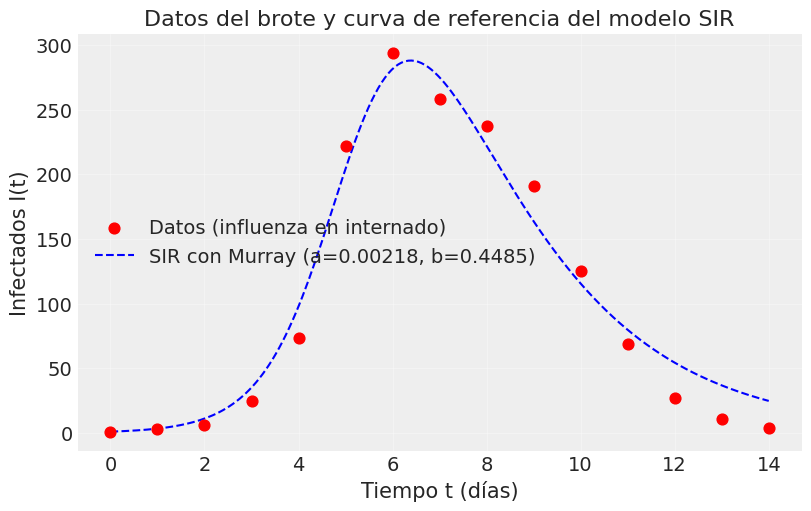

In [56]:
# ---- Figura 1: datos y curva del SIR con los parámetros de Murray ----
a_murray, b_murray = 0.00218, 0.4485
t_fino = np.linspace(0, 14, 200)
curva_murray = odeint(SIR, y0, t_fino, args=((a_murray, b_murray),), rtol=1e-8)

print(f"Modelo (Murray): pico de ≈ {curva_murray[:, 1].max():.0f} infectados "
      f"hacia el día {t_fino[curva_murray[:, 1].argmax()]:.1f}")
print(f"Datos:           pico de  {I_datos.max()} infectados en el día {t_datos[I_datos.argmax()]}")

plt.figure(figsize=(8, 5))
plt.scatter(t_datos, I_datos, color="red", s=60, zorder=5, label="Datos (influenza en internado)")
plt.plot(t_fino, curva_murray[:, 1], "b--", label=f"SIR con Murray (a={a_murray}, b={b_murray})")
plt.xlabel("Tiempo t (días)")
plt.ylabel("Infectados I(t)")
plt.title("Datos del brote y curva de referencia del modelo SIR")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

<span style="color:teal;">**Interpretación de la Figura 1.**</span> El brote es corto y marcado: de 1 infectado se llega a un máximo de **294 en el día 6**, y después baja hasta 4 en el día 14. La curva del SIR con los parámetros de Murray tiene la misma forma de campana, con pico de $≈ 288$ hacia el día 6.4. Por lo que comprobé que la EDO está bien y el modelo es una descripción razonable del brote.

## <span style="color:brown;">**Solver compilado de la EDO dentro de PyMC (la optimización)**</span>

**Por qué era lento.** Con `DifferentialEquation`, cada evaluación del gradiente llamaba a `scipy.integrate.odeint` desde Python, integrando la EDO **más las ecuaciones de sensibilidad**. En la corrida original eso costó ≈ 0.2 s por gradiente y **279 min** en total (≈ 2.8 s por muestra con solo 7–15 evaluaciones de gradiente por muestra: el problema es el costo de cada evaluación, no el número de pasos de NUTS).

**Qué se hace ahora** (función numérica compilada con Numba y conectada a PyMC con un `Op`):

1. Se integra el sistema ampliado
$$(S, I,\frac{ \partial S}{\partial a}, \frac{\partial I}{\partial a},\frac {\partial S}{\partial b},\frac{ \partial I}{\partial b})$$
 con **Runge–Kutta 4 de paso fijo** (40 pasos por día), todo dentro de una función `@njit`. Las sensibilidades cumplen
$$\dot s=\frac{\partial f}{\partial y}\,s+\frac{\partial f}{\partial \theta}.$$
2. El `Op` `SIRInfectados` devuelve $I(t_1..t_{14})$ y su gradiente (producto vector–Jacobiano) para que **NUTS siga funcionando con gradientes exactos**; el modelo y las priors no cambian.
3. Se verifica contra `odeint` (rtol $10^{-12}$) y contra diferencias finitas antes de muestrear.

In [57]:
# ---- Solver SIR + sensibilidades compilado con Numba ----
DIAS = 14          # se observan los días 1..14
PASOS = 40         # pasos RK4 por día (h = 0.025 días; error < 1e-4 infectados, ver verificación)

@njit
def _rhs(y, a, b, out):
    """y = (S, I, dS/da, dI/da, dS/db, dI/db)."""
    S, I, sSa, sIa, sSb, sIb = y[0], y[1], y[2], y[3], y[4], y[5]
    out[0] = -a * S * I
    out[1] = a * S * I - b * I
    out[2] = -a * I * sSa - a * S * sIa - S * I          # d/dt (dS/da)
    out[3] =  a * I * sSa + (a * S - b) * sIa + S * I    # d/dt (dI/da)
    out[4] = -a * I * sSb - a * S * sIb                  # d/dt (dS/db)
    out[5] =  a * I * sSb + (a * S - b) * sIb - I        # d/dt (dI/db)

@njit
def sir_sens(a, b):
    """Devuelve mu[14] = I(1..14) y J[14, 2] = dI/d(a, b)."""
    h = 1.0 / PASOS
    y = np.zeros(6); y[0] = N - 1.0; y[1] = 1.0          # S(0)=762, I(0)=1, sensibilidades 0
    k1 = np.empty(6); k2 = np.empty(6); k3 = np.empty(6); k4 = np.empty(6); tmp = np.empty(6)
    mu = np.empty(DIAS); J = np.empty((DIAS, 2))
    for d in range(DIAS):
        for _ in range(PASOS):
            _rhs(y, a, b, k1)
            for i in range(6): tmp[i] = y[i] + 0.5 * h * k1[i]
            _rhs(tmp, a, b, k2)
            for i in range(6): tmp[i] = y[i] + 0.5 * h * k2[i]
            _rhs(tmp, a, b, k3)
            for i in range(6): tmp[i] = y[i] + h * k3[i]
            _rhs(tmp, a, b, k4)
            for i in range(6): y[i] += h / 6.0 * (k1[i] + 2.0 * k2[i] + 2.0 * k3[i] + k4[i])
        mu[d] = y[1]; J[d, 0] = y[3]; J[d, 1] = y[5]
    if not np.all(np.isfinite(y)):                        # parámetros absurdos: se rechazan
        mu[:] = 1e6; J[:] = 0.0
    return mu, J

class SIRGrad(Op):
    """Producto vector-Jacobiano: (a, b, g) -> (g·dI/da, g·dI/db)."""
    def make_node(self, a, b, g):
        ins = [pt.as_tensor_variable(x) for x in (a, b, g)]
        return Apply(self, ins, [pt.dscalar(), pt.dscalar()])
    def perform(self, node, inputs, outputs):
        a, b, g = inputs
        _, J = sir_sens(float(a), float(b))
        outputs[0][0] = np.array(g @ J[:, 0], dtype=np.float64)
        outputs[1][0] = np.array(g @ J[:, 1], dtype=np.float64)

sir_vjp = SIRGrad()

class SIRInfectados(Op):
    """(a, b) -> I(t=1..14), con gradiente para NUTS."""
    def make_node(self, a, b):
        ins = [pt.as_tensor_variable(x) for x in (a, b)]
        return Apply(self, ins, [pt.dvector()])
    def perform(self, node, inputs, outputs):
        mu, _ = sir_sens(float(inputs[0]), float(inputs[1]))
        outputs[0][0] = mu
    def grad(self, inputs, output_grads):
        a, b = inputs
        return list(sir_vjp(a, b, output_grads[0]))

sir_I = SIRInfectados()

# Versión de SIR compilada para odeint (se usa en las mallas y curvas de las figuras)
@njit
def SIR_nb(y, t, a, b):
    return -a * y[0] * y[1], a * y[0] * y[1] - b * y[1]

# ---- Verificación: contra odeint y contra diferencias finitas ----
a0, b0 = 0.00218, 0.4485
mu_nb, J_nb = sir_sens(a0, b0)                            # primera llamada: compila
ref = odeint(SIR, y0, np.arange(DIAS + 1.0), args=((a0, b0),), rtol=1e-12, atol=1e-12)[1:, 1]
print(f"Error máximo vs odeint: {np.abs(mu_nb - ref).max():.2e} infectados")

a_s_, b_s_ = pt.dscalar("a"), pt.dscalar("b")
grad_fn = pytensor.function([a_s_, b_s_], pt.grad(sir_I(a_s_, b_s_).sum(), [a_s_, b_s_]))
ga, gb = grad_fn(a0, b0)
fd_a = (sir_sens(a0 * (1 + 1e-6), b0)[0].sum() - sir_sens(a0 * (1 - 1e-6), b0)[0].sum()) / (2e-6 * a0)
fd_b = (sir_sens(a0, b0 * (1 + 1e-6))[0].sum() - sir_sens(a0, b0 * (1 - 1e-6))[0].sum()) / (2e-6 * b0)
print(f"Gradiente (Op)          : {ga:.6g}, {gb:.6g}")
print(f"Diferencias finitas     : {fd_a:.6g}, {fd_b:.6g}")

t0 = time.perf_counter()
for _ in range(2000): sir_sens(a0, b0)
print(f"Costo de una evaluación (EDO + sensibilidades): {(time.perf_counter()-t0)/2000*1e6:.0f} µs "
      f"(antes ≈ 200 000 µs)")

Error máximo vs odeint: 2.43e-06 infectados
Gradiente (Op)          : 179275, -3797.17
Diferencias finitas     : 179275, -3797.17
Costo de una evaluación (EDO + sensibilidades): 34 µs (antes ≈ 200 000 µs)


## <span style="color:brown;">**Modelo bayesiano**</span>

<span style="color:magenta;">**Verosimilitud (likelihood)**</span>

Se supone que cada dato varía de forma normal alrededor de la curva del modelo:
$y_i\mid R_0,b,\sigma\sim\mathcal{N}
\!\bigl(I(t_i;a,b),\,\sigma^2\bigr)$. Por tanto,
\begin{equation}
p(\mathbf{y}\mid R_0,b,\sigma)
=\prod_{i=1}^{14}\frac{1}{\sqrt{2\pi}\,\sigma}
\exp\!\left\{-\frac{\bigl(y_i-I(t_i;a,b)\bigr)^2}{2\sigma^2}\right\}
=(2\pi\sigma^2)^{-7}\exp\!\left\{-\frac{\chi^2(a,b)}{2\sigma^2}\right\},
\end{equation}
con
\begin{equation}
\chi^2(a,b)=\sum_{i=1}^{14}\bigl(y_i-I(t_i;a,b)\bigr)^2 .
\end{equation}

<span style="color:magenta;">**Distribuciones a priori (prior)**</span>

Se toman independientes:
\begin{align}
R_0 &\sim \mathcal{N}(2,\,3^2)\ \text{truncada en } R_0>1,
&p(R_0)&\propto \exp\!\left\{-\frac{(R_0-2)^2}{2\cdot 3^2}\right\}\mathbf{1}_{\{R_0>1\}},\\[4pt]
b &\sim \text{LogNormal}(\ln 0.5,\,1),
&p(b)&=\frac{1}{b\sqrt{2\pi}}\exp\!\left\{-\frac{(\ln b-\ln 0.5)^2}{2}\right\},\quad b>0,\\[4pt]
\sigma &\sim \text{HalfNormal}(50),
&p(\sigma)&=\frac{2}{50\sqrt{2\pi}}\exp\!\left\{-\frac{\sigma^2}{2\cdot 50^2}\right\},\quad \sigma>0,
\end{align}
y la prior conjunta es $p(R_0,b,\sigma)=p(R_0)\,p(b)\,p(\sigma)$.

<span style="color:brown;">**Distribución a posteriori (posterior)**</span>

Por el teorema de Bayes,

\begin{equation}
p(R_0,b,\sigma\mid\mathbf{y})
=\frac{p(\mathbf{y}\mid R_0,b,\sigma)\;p(R_0)\,p(b)\,p(\sigma)}{p(\mathbf{y})},
\end{equation}

donde la evidencia es

\begin{equation}
p(\mathbf{y})=\iiint p(\mathbf{y}\mid R_0,b,\sigma)\,p(R_0)\,p(b)\,p(\sigma)\,dR_0\,db\,d\sigma .
\end{equation}
Como $p(\mathbf{y})$ no depende de los parámetros, basta conocer la posterior salvo una constante:
\begin{multline}
p(R_0,b,\sigma\mid\mathbf{y})\;\propto\;
\sigma^{-14}\exp\!\left\{-\frac{\chi^2(a,b)}{2\sigma^2}\right\}
\exp\!\left\{-\frac{(R_0-2)^2}{18}\right\}\mathbf{1}_{\{R_0>1\}}\\
\times\;\frac{1}{b}\exp\!\left\{-\frac{(\ln b-\ln 0.5)^2}{2}\right\}
\exp\!\left\{-\frac{\sigma^2}{5000}\right\},
\end{multline}
con $a=R_0\,b/N$. NUTS (PyMC) solo necesita esta expresi\'on salvo constante.
La posterior de $a$ y la de $I_{max}=N\bigl[1-(1+\ln R_0)/R_0\bigr]$ se obtienen
transformando las muestras de $(R_0,b)$.


Definimos las distribuciones a priori y la verosimilitud

| Elemento | Distribución | Por qué |
|---|---|---|
| $\sigma$ | HalfNormal(50) | Error típico de los datos, positivo. Prior débil: admite errores desde unos pocos hasta ~100 infectados. |
| $R_0$ | Normal(2, 3) truncada en $R_0>1$ | Como el artículo: sabemos que hubo epidemia, lo que implica $R_0>1$. |
| $b$ | LogNormal($\ln0.5$, 1) | Debe ser positiva; mediana de 0.5 por día (infección de ~2 días); rango a priori 95 % ≈ 0.07 a 3.5. |
| $a$ | $a=\frac{R_0\,b}{N}$ | Se deriva de $R_0$ y $b$, porque $R_0=\frac{aN}{b}$. |
| $I_{obs}$ | Normal($I_{modelo}$, $\sigma$) | Los datos varían alrededor de la curva del modelo. |

Es más fácil dar una prior razonable a $R_0$ (cuántas personas contagia un infectado) que a la tasa $a$, cuya escala depende de $N$. Por eso parametrizamos con $R_0$ y $b$.

In [58]:
# ---- Modelo bayesiano ----
with pm.Model() as modelo_sir:
    # (1) Error típico de los datos (en número de infectados), también se estima
    sigma = pm.HalfNormal("sigma", 50)

    # (2) Número reproductivo: acotado por abajo en 1 porque sabemos que hubo epidemia
    R0 = pm.TruncatedNormal("R0", mu=2, sigma=3, lower=1)

    # (3) Tasa de recuperación b (por día): positiva, mediana a priori 0.5 por día
    b = pm.LogNormal("b", mu=np.log(0.5), sigma=1)

    # (4) Tasa de transmisión a, derivada de R0 y b:  R0 = a·N / b  =>  a = R0·b / N
    a = pm.Deterministic("a", R0 * b / N)

    # (5) Infectados del SIR en los días 1..14 para (a, b), con el solver compilado (Numba)
    I_modelo = sir_I(a, b)

    # (6) Verosimilitud: los infectados observados se distribuyen normal alrededor del modelo
    pm.Normal("I_obs", mu=I_modelo, sigma=sigma, observed=I_obs)

Para el <span style="color:purple;">**Muestreo**</span> usamos `pm.sample`, que obtiene muestras de la distribución posterior de $(R_0,b,\sigma)$ con NUTS.

* `tune=1000`: iteraciones de calentamiento, que luego se descartan (equivale al *burn-in*).
* `draws=2000`: muestras que se guardan por cadena; `chains=4` cadenas independientes, para comprobar que llegan a lo mismo (8000 muestras en total; antes 15 000, con un ESS de ≈ 4800 sobraba).
* `target_accept=0.9`: pasos más cuidadosos, para evitar divergencias.
* `init="jitter+adapt_full"`: durante el calentamiento se aprende una **matriz de masas completa**. Como $R_0$ y $b$ tienen correlación posterior ≈ −0.9, esto permite pasos más largos y menos evaluaciones de gradiente por muestra.
* `cores`: una cadena por procesador disponible (el solver compilado ya no necesita `cores=1`).

> **Tiempo:** la corrida original (EDO con SciPy desde Python) tardó **16 732 s ≈ 279 min**. Con el solver compilado cada gradiente cuesta microsegundos, por lo que el muestreo debería tardar del orden de segundos a pocos minutos.

In [59]:
# ---- Muestreo ----
inicio = time.time()    # momento en que empieza
with modelo_sir:
    idata = pm.sample(15000, tune=15000, chains=5, cores=min(4, os.cpu_count() or 1),
                      init="jitter+adapt_full", target_accept=0.9, random_seed=42)
fin = time.time()                         # momento en que termina
duracion = fin - inicio                   # segundos transcurridos
print(f"Duración del muestreo: {duracion:.1f} segundos ({duracion/60:.1f} minutos)")
print(f"Corrida original: 16732.3 s  ->  aceleración ≈ {16732.3/duracion:.0f}x")

/usr/local/lib/python3.13/dist-packages/pymc/step_methods/hmc/quadpotential.py:760: UserWarning: QuadPotentialFullAdapt is an experimental feature
  warnings.warn("QuadPotentialFullAdapt is an experimental feature")


Output()

Duración del muestreo: 275.6 segundos (4.6 minutos)
Corrida original: 16732.3 s  ->  aceleración ≈ 61x


Para analizar la convergencia comprobamos que el muestreo funciono con ellos nos apoyamos de lo siguiente:


> * `az.summary` da media, desviación, intervalo del 95 % y dos diagnósticos: **$\hat R$** (debe ser ≈ 1.00, y menor que 1.01) y el tamaño efectivo de muestra **ESS** (cientos o más).
> * Las **transiciones divergentes** deben ser 0.
> * Graficamos y la llamaré **Figura 2:** a la izquierda, la distribución de cada parámetro por cadena; a la derecha, la traza.

         mean     sd  hdi_2.5%  hdi_97.5%  mcse_mean  mcse_sd  ess_bulk  \
R0      3.737  0.143     3.448      4.017      0.001    0.001   57880.0   
b       0.446  0.018     0.411      0.484      0.000    0.000   58546.0   
a       0.002  0.000     0.002      0.002      0.000    0.000   57821.0   
sigma  21.498  4.958    13.201     31.233      0.025    0.027   42518.0   

       ess_tail  r_hat  
R0      44780.0    1.0  
b       45402.0    1.0  
a       44791.0    1.0  
sigma   42996.0    1.0  

Transiciones divergentes: 0


/tmp/ipykernel_1319/2490527014.py:10: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


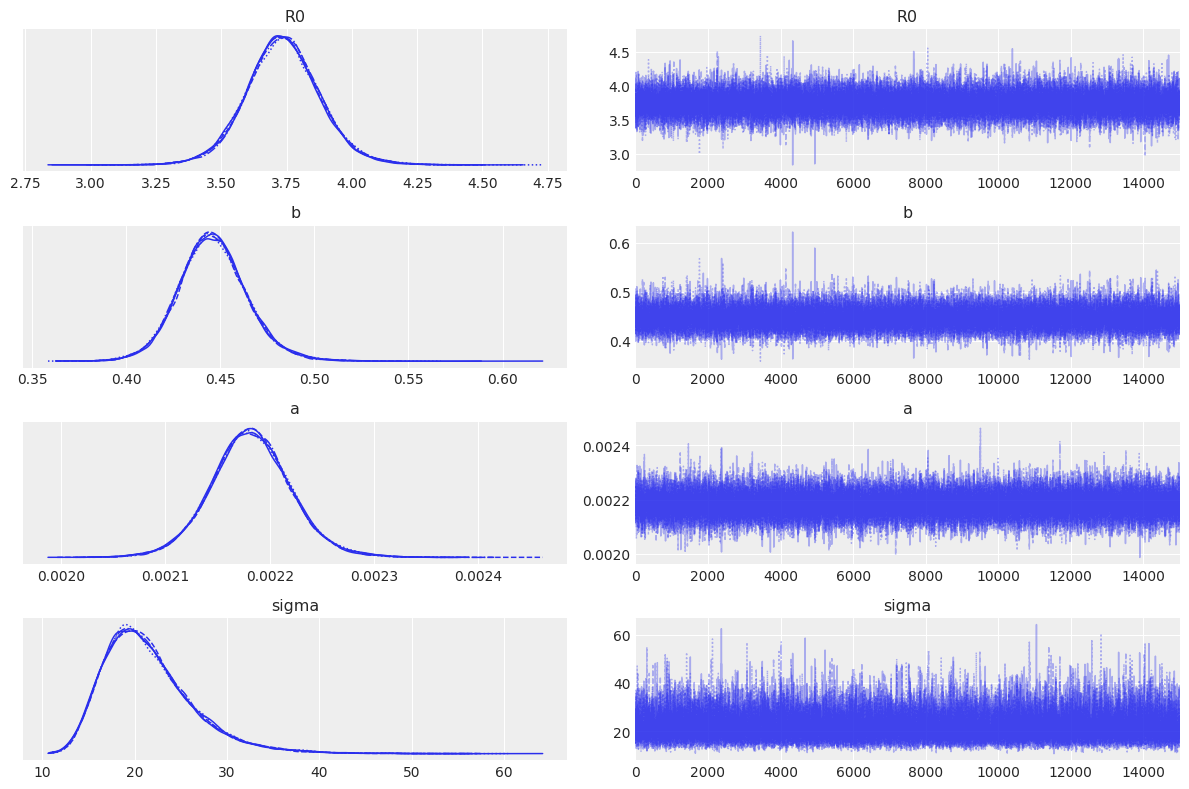

In [60]:
# ---- Diagnóstico de convergencia ----
resumen = az.summary(idata, var_names=["R0", "b", "a", "sigma"], hdi_prob=0.95)
print(resumen)

n_div = int(idata.sample_stats["diverging"].sum())
print(f"\nTransiciones divergentes: {n_div}")

# ---- Figura 2: trazas de las cadenas y distribuciones por cadena ----
az.plot_trace(idata, var_names=["R0", "b", "a", "sigma"])
plt.tight_layout()
plt.show()

<span style="color:teal;">**Interpretación de la Figura 2.**</span>

* Las cadenas se **superponen** en las distribuciones de la izquierda.
* Las trazas de la derecha parecen estables alrededor de un valor constante, sin tendencias ni tramos pegados.
* NO hay ninguna divergencia.


*Detalle:* $R_0$ y $b$ están **fuertemente correlacionados**

Para las <span style="color:magenta;">**Distribuciones posteriores**</span>
juntamos las cadenas y se grafica la distribución posterior de $R_0$, $b$, $a$ y $\sigma$, con su media y el intervalo de credibilidad del 95 %.

/tmp/ipykernel_1319/2407661050.py:21: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


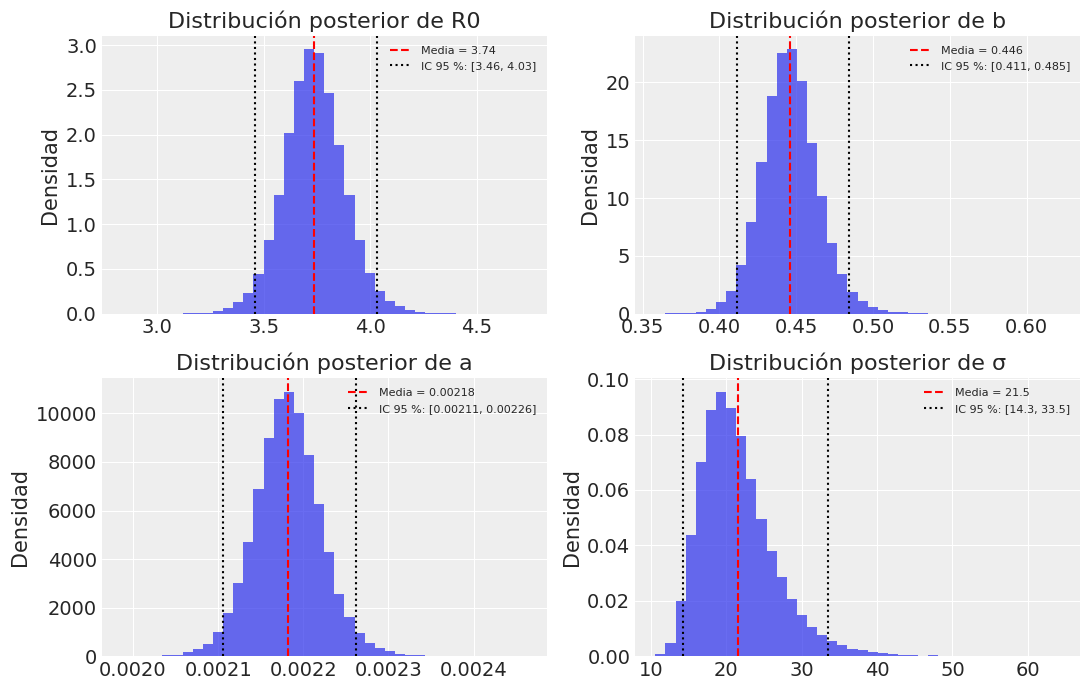

Correlación posterior entre R0 y b: -0.90


In [61]:
# ---- Muestras posteriores (se juntan las cadenas en un solo vector por parámetro) ----
post = idata.posterior
R0_s = post["R0"].values.flatten()
b_s = post["b"].values.flatten()
a_s = post["a"].values.flatten()
sigma_s = post["sigma"].values.flatten()

# ---- Figura 3: distribuciones posteriores con media e intervalo de credibilidad del 95 % ----
parametros = [("R0", R0_s, ".2f"), ("b", b_s, ".3f"), ("a", a_s, ".5f"), ("σ", sigma_s, ".1f")]

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, (nombre, v, fmt) in zip(axes.ravel(), parametros):
    lo, hi = np.percentile(v, [2.5, 97.5])
    ax.hist(v, bins=40, density=True, alpha=0.7)
    ax.axvline(v.mean(), color="red", linestyle="--", label=f"Media = {v.mean():{fmt}}")
    ax.axvline(lo, color="black", linestyle=":", label=f"IC 95 %: [{lo:{fmt}}, {hi:{fmt}}]")
    ax.axvline(hi, color="black", linestyle=":")
    ax.set_title(f"Distribución posterior de {nombre}")
    ax.set_ylabel("Densidad")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"Correlación posterior entre R0 y b: {np.corrcoef(R0_s, b_s)[0, 1]:.2f}")

### <span style="color:teal;">**Comparamos  El óvalo de $\chi^2$ y la posterior de PyMC**</span>

Esta gráfica sera la **Figura 4** se muestra la superficie de $\chi^2(a,b)$ de la práctica anterior (el "óvalo") junto con las muestras posteriores de PyMC, para ver que ambos métodos describen la misma región de parámetros. A la izquierda está la vista general; a la derecha, un acercamiento a la zona de la posterior.

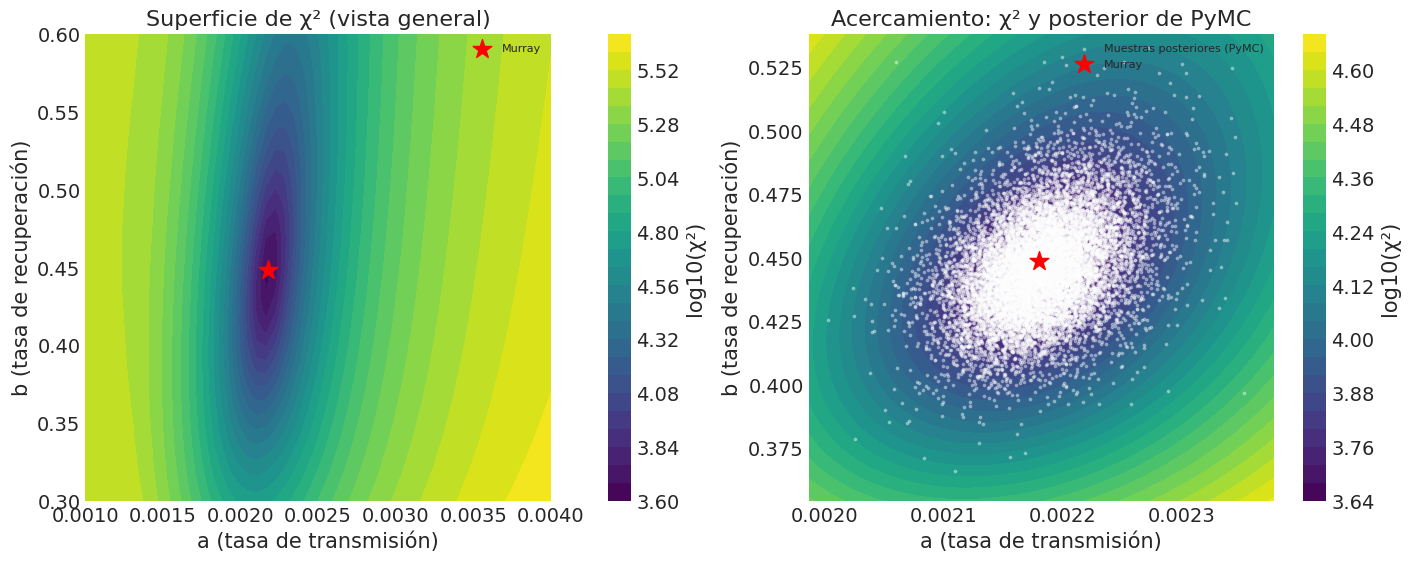

In [62]:
# ---- Figura 4: la superficie de χ² (el "óvalo") y la posterior de PyMC ----
def chi2_malla(a, b):
    """χ²(a,b) = suma de (I_obs - I_modelo)², con σ = 1 (igual que en la práctica anterior)."""
    sol = odeint(SIR_nb, y0, np.r_[0, t_obs], args=(a, b), rtol=1e-8)
    return np.sum((I_obs - sol[1:, 1]) ** 2)

def malla_chi2(a_vals, b_vals):
    Z = np.zeros((len(b_vals), len(a_vals)))
    for i, ai in enumerate(a_vals):
        for j, bj in enumerate(b_vals):
            Z[j, i] = chi2_malla(ai, bj)
    return Z

# Usamos layout="constrained" para manejar correctamente el espacio con colorbars sin usar tight_layout
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), layout="constrained")

# (izquierda) vista general, la misma malla de la práctica anterior
a_g = np.linspace(0.001, 0.004, 50)
b_g = np.linspace(0.3, 0.6, 50)
cs = axes[0].contourf(a_g, b_g, np.log10(malla_chi2(a_g, b_g)), levels=30, cmap="viridis")
fig.colorbar(cs, ax=axes[0], label="log10(χ²)")
axes[0].scatter(a_murray, b_murray, color="red", marker="*", s=200, label="Murray")
axes[0].set_title("Superficie de χ² (vista general)")

# (derecha) acercamiento a la zona donde está la posterior, con las muestras de PyMC
a_c, a_d = a_s.mean(), a_s.std()
b_c, b_d = b_s.mean(), b_s.std()
a_z = np.linspace(a_c - 5 * a_d, a_c + 5 * a_d, 60)
b_z = np.linspace(b_c - 5 * b_d, b_c + 5 * b_d, 60)
cz = axes[1].contourf(a_z, b_z, np.log10(malla_chi2(a_z, b_z)), levels=30, cmap="viridis")
fig.colorbar(cz, ax=axes[1], label="log10(χ²)")
axes[1].scatter(a_s[::5], b_s[::5], s=3, color="white", alpha=0.35, label="Muestras posteriores (PyMC)")
axes[1].scatter(a_murray, b_murray, color="red", marker="*", s=200, label="Murray")
axes[1].set_title("Acercamiento: χ² y posterior de PyMC")
axes[1].set_xlim(a_z[0], a_z[-1])      # recortar a la malla calculada
axes[1].set_ylim(b_z[0], b_z[-1])

for ax in axes:
    ax.set_xlabel("a (tasa de transmisión)")
    ax.set_ylabel("b (tasa de recuperación)")
    ax.legend(loc="upper right", fontsize=8)

plt.show()

<span style="color:teal;">**Interpretación de la Figura 4.**</span>
* **Vista general:** $\chi^2$ tiene un único valle en forma de óvalo alargado: angosto en $a$ y largo en $b$. Murray (estrella roja) está en el centro. El fondo del óvalo es el par $(a,b)$ de mínimos cuadrados.
* **Acercamiento:** las muestras posteriores de PyMC forman una **nube elíptica que cae dentro del óvalo** y sigue su forma. Se inclina hacia arriba a la derecha, es decir, $a$ y $b$ están correlacionados positivamente: un $b$ mayor se compensa con un $a$ mayor.
* **Por qué coinciden:** con verosimilitud normal, la posterior es proporcional a $e^{-\chi^2/(2\sigma^2)}$ (por la prior). Es el mismo óvalo, pero con la escala fijada por $\sigma$. Como se estimó $\sigma\approx21$ (y no 1), la nube es mucho más ancha que la zona de $\chi^2$ mínimo con $\sigma=1$.
* **Murray** queda dentro de la nube, así que es compatible con los datos.

### <span style="color:teal;">Posterior conjunta de $(a,b)$: el óvalo</span>

**Figura 5**: las gráficas anteriores muestran $a$ y $b$ por separado. Esta figura muestra su distribución **conjunta**: la forma de óvalo indica cuáles combinaciones de $(a,b)$ son compatibles con los datos, y cuánto dependen una de otra. Se dibujan las regiones de credibilidad del 50 % y del 95 % estimadas con las muestras de PyMC.

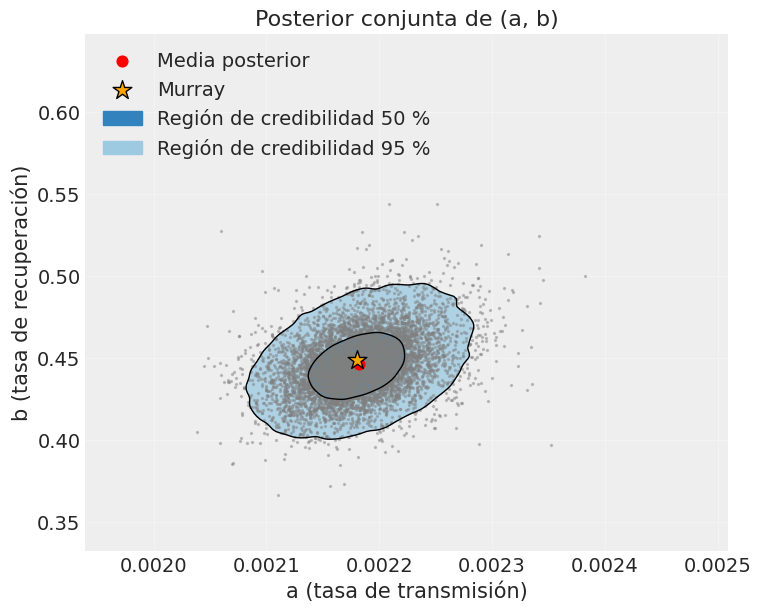

Correlación posterior entre a y b: 0.37
¿Murray dentro de la región del 95 %? True


In [63]:
# ---- Figura 5: posterior conjunta de (a, b): el óvalo ----
from scipy.stats import gaussian_kde
from matplotlib.patches import Patch

puntos = np.vstack([a_s, b_s])
kde = gaussian_kde(puntos)                  # estima la densidad conjunta a partir de las muestras
dens = kde(puntos)                          # densidad evaluada en cada muestra

# Una muestra tiene densidad >= nivel_95 en el 95 % de los casos (igual con el 50 %)
nivel_95 = np.percentile(dens, 5)
nivel_50 = np.percentile(dens, 50)

# Malla para dibujar las curvas de nivel
a_ext = np.linspace(a_s.min() - 0.1 * np.ptp(a_s), a_s.max() + 0.1 * np.ptp(a_s), 200)
b_ext = np.linspace(b_s.min() - 0.1 * np.ptp(b_s), b_s.max() + 0.1 * np.ptp(b_s), 200)
A_, B_ = np.meshgrid(a_ext, b_ext)
Zk = kde(np.vstack([A_.ravel(), B_.ravel()])).reshape(A_.shape)

fig, ax = plt.subplots(figsize=(7.5, 6))
ax.contourf(A_, B_, Zk, levels=[nivel_95, nivel_50, Zk.max()],
            colors=["#9ecae1", "#3182bd"], alpha=0.8)          # regiones de credibilidad
ax.contour(A_, B_, Zk, levels=[nivel_95, nivel_50], colors="k", linewidths=1)
ax.scatter(a_s[::10], b_s[::10], s=2, color="gray", alpha=0.4)  # muestras (una de cada 10)
ax.scatter(a_s.mean(), b_s.mean(), color="red", s=60, zorder=5, label="Media posterior")
ax.scatter(a_murray, b_murray, color="orange", marker="*", s=200, edgecolor="k",
           zorder=5, label="Murray")
ax.set_xlim(a_ext[0], a_ext[-1])
ax.set_ylim(b_ext[0], b_ext[-1])

handles, _ = ax.get_legend_handles_labels()
ax.legend(handles=handles + [Patch(color="#3182bd", label="Región de credibilidad 50 %"),
                             Patch(color="#9ecae1", label="Región de credibilidad 95 %")],
          loc="upper left")
ax.set_xlabel("a (tasa de transmisión)")
ax.set_ylabel("b (tasa de recuperación)")
ax.set_title("Posterior conjunta de (a, b)")
ax.grid(True, alpha=0.3)
plt.show()

print(f"Correlación posterior entre a y b: {np.corrcoef(a_s, b_s)[0, 1]:.2f}")
print("¿Murray dentro de la región del 95 %?",
      bool(kde([[a_murray], [b_murray]])[0] >= nivel_95))

<span style="color:teal;">**Interpretación de la Figura 5.**</span>

* Las muestras forman un **óvalo inclinado hacia arriba a la derecha**: $a$ y $b$ están correlacionados positivamente se compensa con un $a$ mayor (más contagio) y la curva del brote casi no cambia.
* El **tamaño** del óvalo es la incertidumbre: su ancho horizontal es la de $a$ y su alto vertical, la de $b$. La región del 95 % encierra casi todas las combinaciones razonables, y la del 50 % las más probables.
* La media posterior queda en el centro y Murray cae **dentro** de la región del 95 % (la celda lo comprueba), así que es compatible con los datos.
* Es el mismo óvalo que el valle de $\chi^2$ de la Figura 5, pero con la escala fijada por $\sigma$ y suavizado por las priors.

### <span style="color:brown;"> **Ajuste del modelo con incertidumbre**
</span>

Tomamos 300 muestras posteriores de $(a,b)$ y con cada una se resuelve el SIR, lo que da 300 curvas posibles. Su dispersión muestra cuánta incertidumbre hay en la curva. Se agrega una segunda banda que además suma el ruido de observación $N(0,\sigma^2)$, que indica dónde se esperaría que caigan los datos observados.

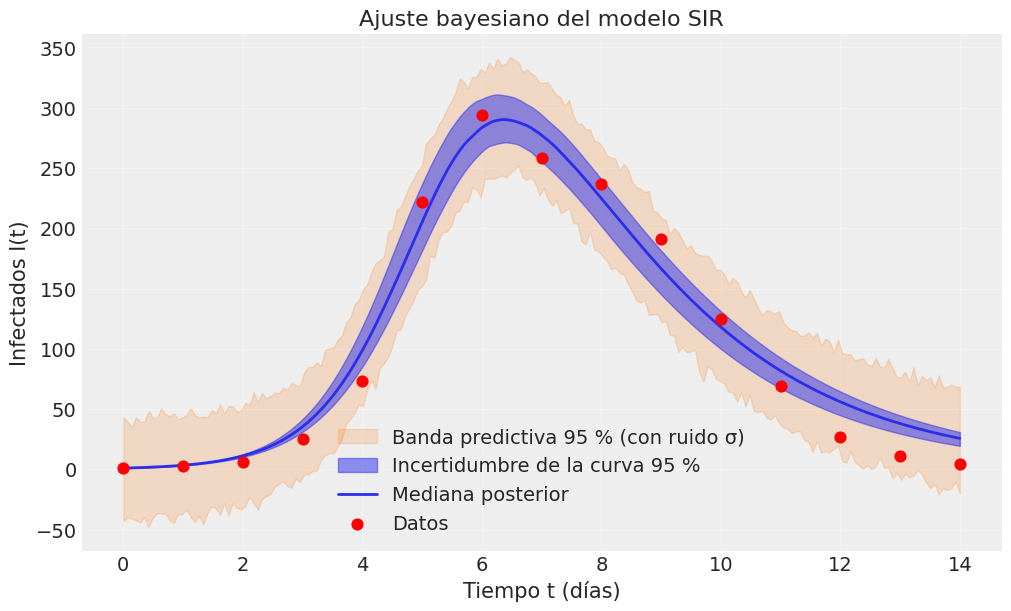

In [64]:
# ---- Figura 6: ajuste del modelo con incertidumbre ----
rng = np.random.default_rng(0)
idx = rng.choice(len(a_s), size=min(300, len(a_s)), replace=False)   # 300 muestras posteriores al azar

# Una curva de infectados por cada muestra posterior (a, b)
curvas_post = np.array([odeint(SIR_nb, y0, t_fino, args=(a_s[i], b_s[i]), rtol=1e-8)[:, 1]
                        for i in idx])
# Lo mismo, pero sumando el ruido de observación N(0, σ): banda "predictiva"
curvas_pred = curvas_post + rng.normal(0, sigma_s[idx][:, None], size=curvas_post.shape)

I_med = np.median(curvas_post, axis=0)
mu_lo, mu_hi = np.percentile(curvas_post, [2.5, 97.5], axis=0)
pr_lo, pr_hi = np.percentile(curvas_pred, [2.5, 97.5], axis=0)

plt.figure(figsize=(10, 6))
plt.fill_between(t_fino, pr_lo, pr_hi, color="C1", alpha=0.2, label="Banda predictiva 95 % (con ruido σ)")
plt.fill_between(t_fino, mu_lo, mu_hi, color="C0", alpha=0.5, label="Incertidumbre de la curva 95 %")
plt.plot(t_fino, I_med, color="C0", linewidth=2, label="Mediana posterior")
plt.scatter(t_datos, I_datos, color="red", s=60, zorder=5, label="Datos")
plt.xlabel("Tiempo t (días)")
plt.ylabel("Infectados I(t)")
plt.title("Ajuste bayesiano del modelo SIR")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

<span style="color:teal;">**Interpretación de la Figura 6.**<span>
* La **mediana posterior** reproduce el crecimiento, el pico  y la bajada.
* La banda azul (incertidumbre de la curva) es angosta: los datos determinan bien la curva promedio.
* La banda naranja (predictiva) es mucho más ancha, porque incluye el ruido σ. Con los valores de referencia, **los 14 datos caen dentro de la banda del 95 %**, es decir, el modelo describe los datos de forma coherente.
* Hay un patrón que el modelo no captura: los datos de los días 12 a 14 quedan **sistemáticamente por debajo** de la curva (el SIR baja más lento que el brote real). Un buen ajuste tendría residuos sin patrón, así que esto muestra una limitación del modelo (recuperación constante, población homogénea) y no del método de inferencia.
* La banda predictiva llega a valores negativos en los primeros y en los últimos días: la verosimilitud normal admite infectados negativos.

Finalmente calculamos el <span style="color:magenta;">**Número reproductivo, máximo de infectados y comparación**</span> dado que la posterior de $R_0$ es una distribución, el máximo de infectados $I_{max}=N\left[1-\frac{1+\ln R_0}{R_0}\right]$ también lo es, y se calcula con cada muestra. Al final se comparamos con Murray y con el método $\chi^2$ + Metropolis-Hastings propio de la práctica anterior.

In [65]:
 #---- Máximo de infectados a partir de R0 ----
Imax_s = N * (1 - (1 + np.log(R0_s)) / R0_s)      # I_max = N·[1 - (1 + ln R0)/R0]
print(f"R0    = {R0_s.mean():.2f}   IC 95 %: [{np.percentile(R0_s, 2.5):.2f}, {np.percentile(R0_s, 97.5):.2f}]")
print(f"I_max = {Imax_s.mean():.0f} personas   IC 95 %: [{np.percentile(Imax_s, 2.5):.0f}, {np.percentile(Imax_s, 97.5):.0f}]")
print(f"Máximo observado en los datos: {I_datos.max()} personas")

# ---- Comparación con los otros métodos (valores de la práctica anterior) ----
print("\nMétodo                     a           b        R0")
print(f"Murray                  0.002180    0.4485    {0.00218 * N / 0.4485:.2f}")
print(f"χ² + MH (propio)        0.002181    0.4452    {0.002181 * N / 0.4452:.2f}")
print(f"PyMC (media posterior)  {a_s.mean():.6f}    {b_s.mean():.4f}    {R0_s.mean():.2f}")

R0    = 3.74   IC 95 %: [3.46, 4.03]
I_max = 289 personas   IC 95 %: [269, 310]
Máximo observado en los datos: 294 personas

Método                     a           b        R0
Murray                  0.002180    0.4485    3.71
χ² + MH (propio)        0.002181    0.4452    3.74
PyMC (media posterior)  0.002182    0.4461    3.74


## <span style="color:purple;">**Conclusión**</span>

* El modelo SIR bayesiano en PyMC (EDO + priors + verosimilitud normal) estima $R_0\approx3.7$, $b\approx0.45$ por día ($\approx2$ días de infección) y $a\approx0.0022$, con intervalos de credibilidad.
* La convergencia se comprueba con $\hat R$, el ESS, las divergencias y las trazas; solo después se interpretan los resultados.
* Las estimaciones coinciden con Murray y con el ajuste $\chi^2$ + Metropolis-Hastings, lo que valida los tres métodos. La ventaja del enfoque bayesiano está en cuantificar la incertidumbre y estimar $\sigma$, sin fijarla.
* El máximo de infectados que se predice (≈ 289) concuerda con el observado (294); estimar los parámetros permite anticipar el tamaño del pico, útil para decisiones de salud pública.

<span style="color:red;">**Limitaciones**</span>
* El SIR simple sobrestima los últimos días del brote (residuos con patrón en los días 12 a 14).
* La verosimilitud normal con $\sigma$ constante admite valores negativos y no depende del nivel de $I(t)$; para conteos convendría una binomial negativa o un error proporcional al nivel.
* `DifferentialEquation` es lento comparado con otros resolvedores (existen alternativas más rápidas, como `sunode`).
* Las priors son débiles; con pocos datos podrían influir más, y conviene revisar su efecto cambiándolas.